# 표 질의응답

표가 많은 통계 보도자료 2건을 대상으로, 표 특화 Multimodal RAG 전략을 실습합니다.

- `data/online_shopping_trend.pdf` (온라인쇼핑동향, 5p)
- `data/population_dynamics_survey.pdf` (인구동향조사, 15p)
- 전략: 표 페이지를 **이미지로 보존**하면서 동시에 **마크다운 텍스트로 변환**해 정확한 셀 값 조회에 활용하고, 원본 이미지로 검증


## 1. 두 문서를 페이지 이미지로 렌더링

In [1]:
from pathlib import Path

import chromadb
import fitz
from tqdm import tqdm

from rag_utils import ask_vlm, summarize_image, embed_text, show

DOCS = {
    "online_shopping_trend": Path("./data/online_shopping_trend.pdf"),
    "population_dynamics_survey": Path("./data/population_dynamics_survey.pdf"),
}

page_records = []  # {"doc_id", "source", "page", "image_path"}

for source, pdf_path in DOCS.items():
    out_dir = Path(f"./pages/{source}")
    out_dir.mkdir(parents=True, exist_ok=True)

    doc = fitz.open(pdf_path)
    for i, page in enumerate(doc):
        pix = page.get_pixmap(dpi=150)
        image_path = out_dir / f"page_{i:02d}.png"
        pix.save(image_path)
        page_records.append(
            {
                "doc_id": f"{source}_{i:02d}",
                "source": source,
                "page": i,
                "image_path": str(image_path),
            }
        )

print(f"총 {len(page_records)}개 페이지를 렌더링했습니다.")


총 20개 페이지를 렌더링했습니다.


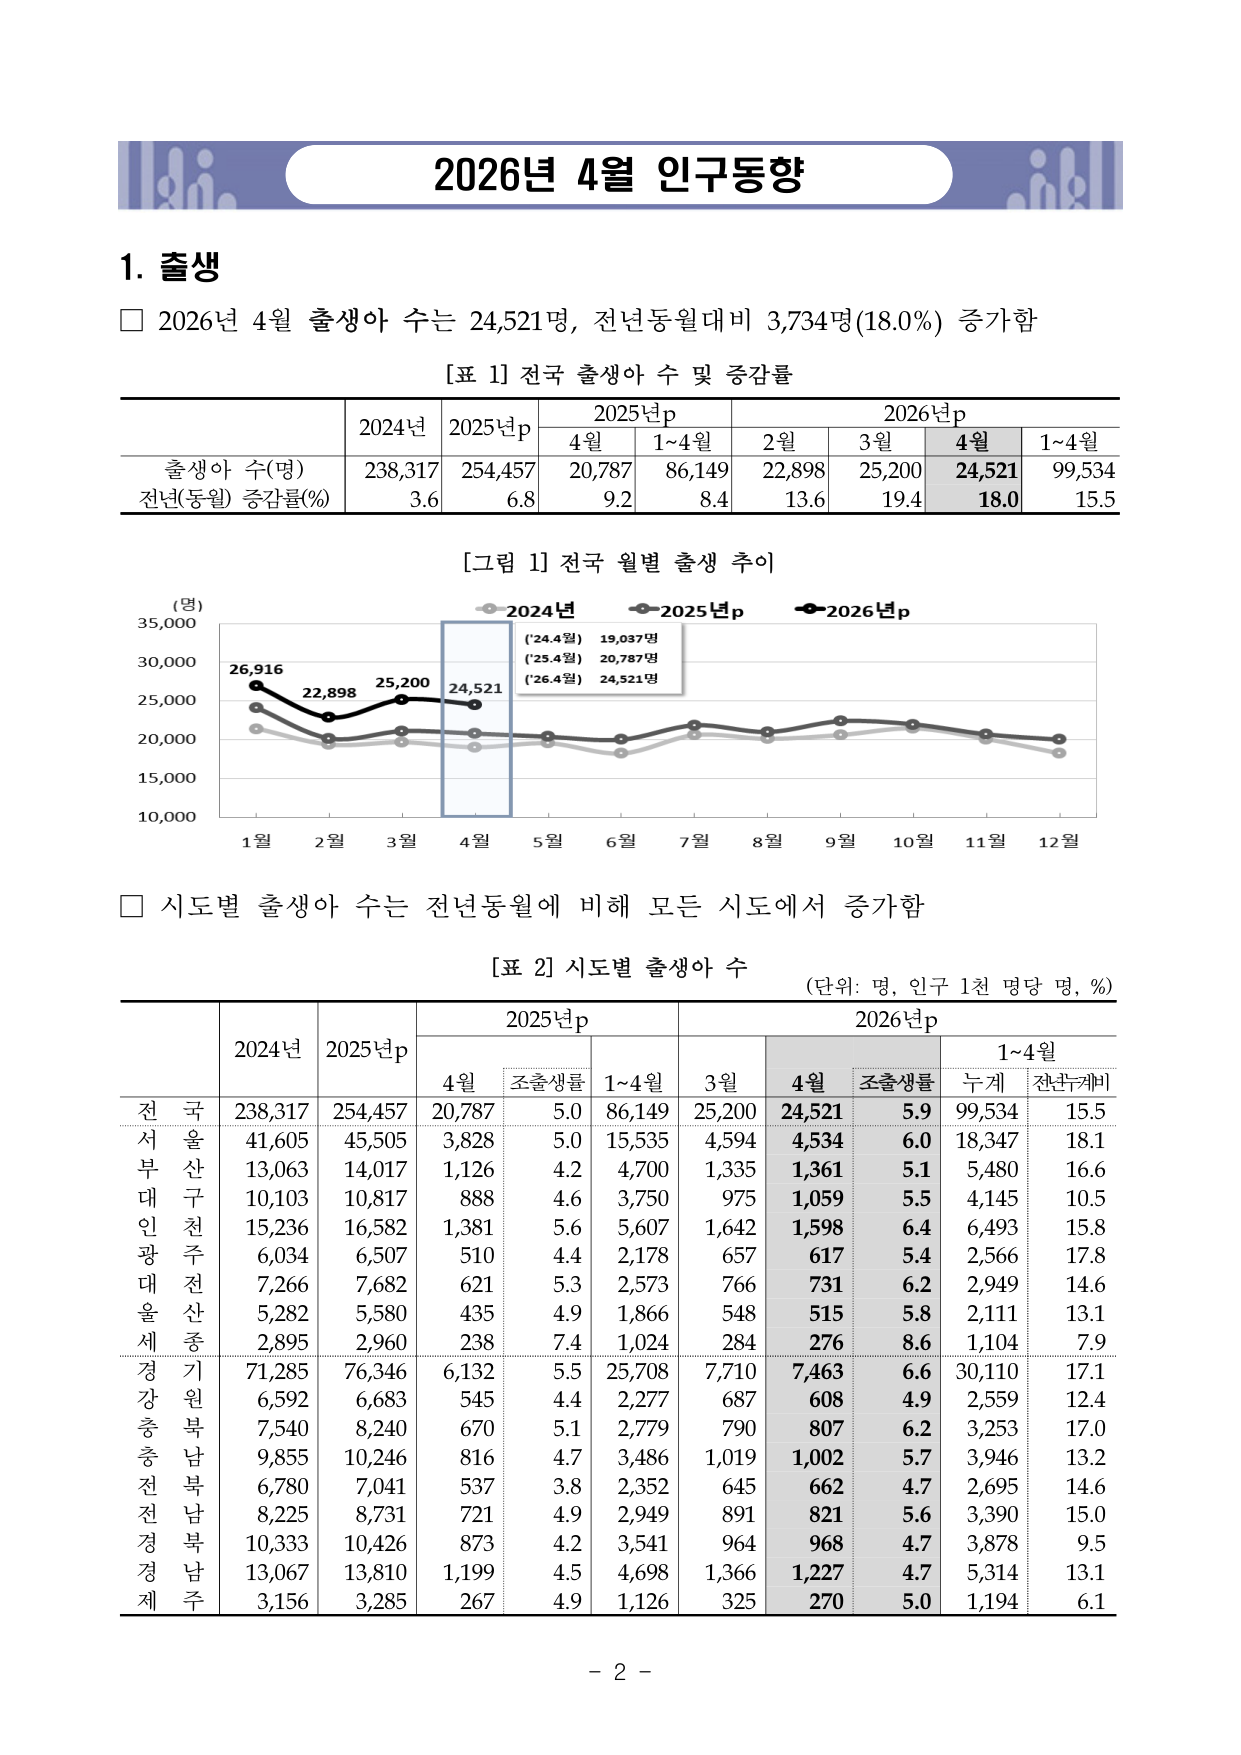

In [2]:
# 표가 있는 페이지 미리보기 (인구동향조사 - [표 1] 전국 출생아 수 및 증감률)
sample = next(
    r
    for r in page_records
    if r["source"] == "population_dynamics_survey" and r["page"] == 4
)
show(sample["image_path"])


## 2. 표를 마크다운으로 변환하기
- OCR 대신 **VLM에게 표를 마크다운 표로 변환**해 달라고 요청 → 정확한 셀 단위 조회에 활용
- 표가 없는 페이지는 핵심 내용을 요약


In [3]:
TABLE_INSTRUCTION = (
    "이 페이지 이미지에 표가 있다면 행과 열을 그대로 살려 마크다운 표로 정확하게 변환해줘. "
    "표가 없다면 페이지의 핵심 내용을 3~5문장으로 요약해줘."
)

for record in tqdm(page_records, desc="표 변환/요약"):
    record["markdown"] = summarize_image(record["image_path"], TABLE_INSTRUCTION)

print(sample["markdown"] if "markdown" in sample else page_records[0]["markdown"])


표 변환/요약: 100%|██████████| 20/20 [02:04<00:00,  6.25s/it]

### 2026년 4월 인구동향 요약

2026년 4월 출생아 수는 24,521명으로, 전년 동월 대비 3,734명(18.0%) 증가했습니다. 2025년 4월 출생아 수는 20,787명이었으며, 2024년 4월과 비교할 때 증가율은 8.4%입니다. 또한, 시도별 출생아 수는 모든 시도에서 전년 동월 대비 증가하였으며, 각 지역별 출생아 수의 변화도 나타났습니다.


## 3. Vector Store에 저장 (두 문서를 하나의 컬렉션으로)

In [4]:
client = chromadb.PersistentClient(path="./chroma_db")
collection = client.get_or_create_collection(
    name="stat_reports",
    metadata={"hnsw:space": "cosine"},
)

embeddings = [embed_text(record["markdown"]) for record in tqdm(page_records, desc="임베딩")]

collection.add(
    ids=[r["doc_id"] for r in page_records],
    embeddings=embeddings,
    documents=[r["markdown"] for r in page_records],
    metadatas=[
        {"source": r["source"], "page": r["page"], "image_path": r["image_path"]}
        for r in page_records
    ],
)

print(f"{collection.count()}개 페이지가 저장되었습니다.")


임베딩: 100%|██████████| 20/20 [00:08<00:00,  2.48it/s]

20개 페이지가 저장되었습니다.


## 4. 표 질의응답 실습
검색된 **마크다운 표(텍스트본)**와 **원본 이미지**를 함께 VLM에 전달해, 정확한 셀 값 조회와 원본 검증을 동시에 수행합니다.


In [5]:
def ask_table(question, k=2):
    query_embedding = embed_text(question)
    results = collection.query(query_embeddings=[query_embedding], n_results=k)

    metadatas = results["metadatas"][0]
    markdowns = results["documents"][0]
    image_paths = [m["image_path"] for m in metadatas]

    context = "\n\n".join(
        f"[출처: {m['source']} {m['page']}페이지]\n{md}"
        for m, md in zip(metadatas, markdowns)
    )

    prompt = (
        "아래는 검색된 표(마크다운 변환본)와 그 출처야. 원본 이미지도 함께 참고해서 질문에 답해줘.\n"
        "변환 과정에서 값이 누락되거나 어색해 보이면 원본 이미지 기준으로 정정해줘.\n\n"
        f"{context}\n\n질문: {question}"
    )

    return ask_vlm(prompt, image_paths), metadatas


answer, metadatas = ask_table(
    "2026년 5월 온라인쇼핑 총 거래액은 얼마이고, 전년동월대비 얼마나 증가했어?"
)
print(answer)


2026년 5월 온라인쇼핑 총 거래액은 25조 130억 원이며, 전년 동월 대비 10.3% 증가했습니다.


online_shopping_trend 3


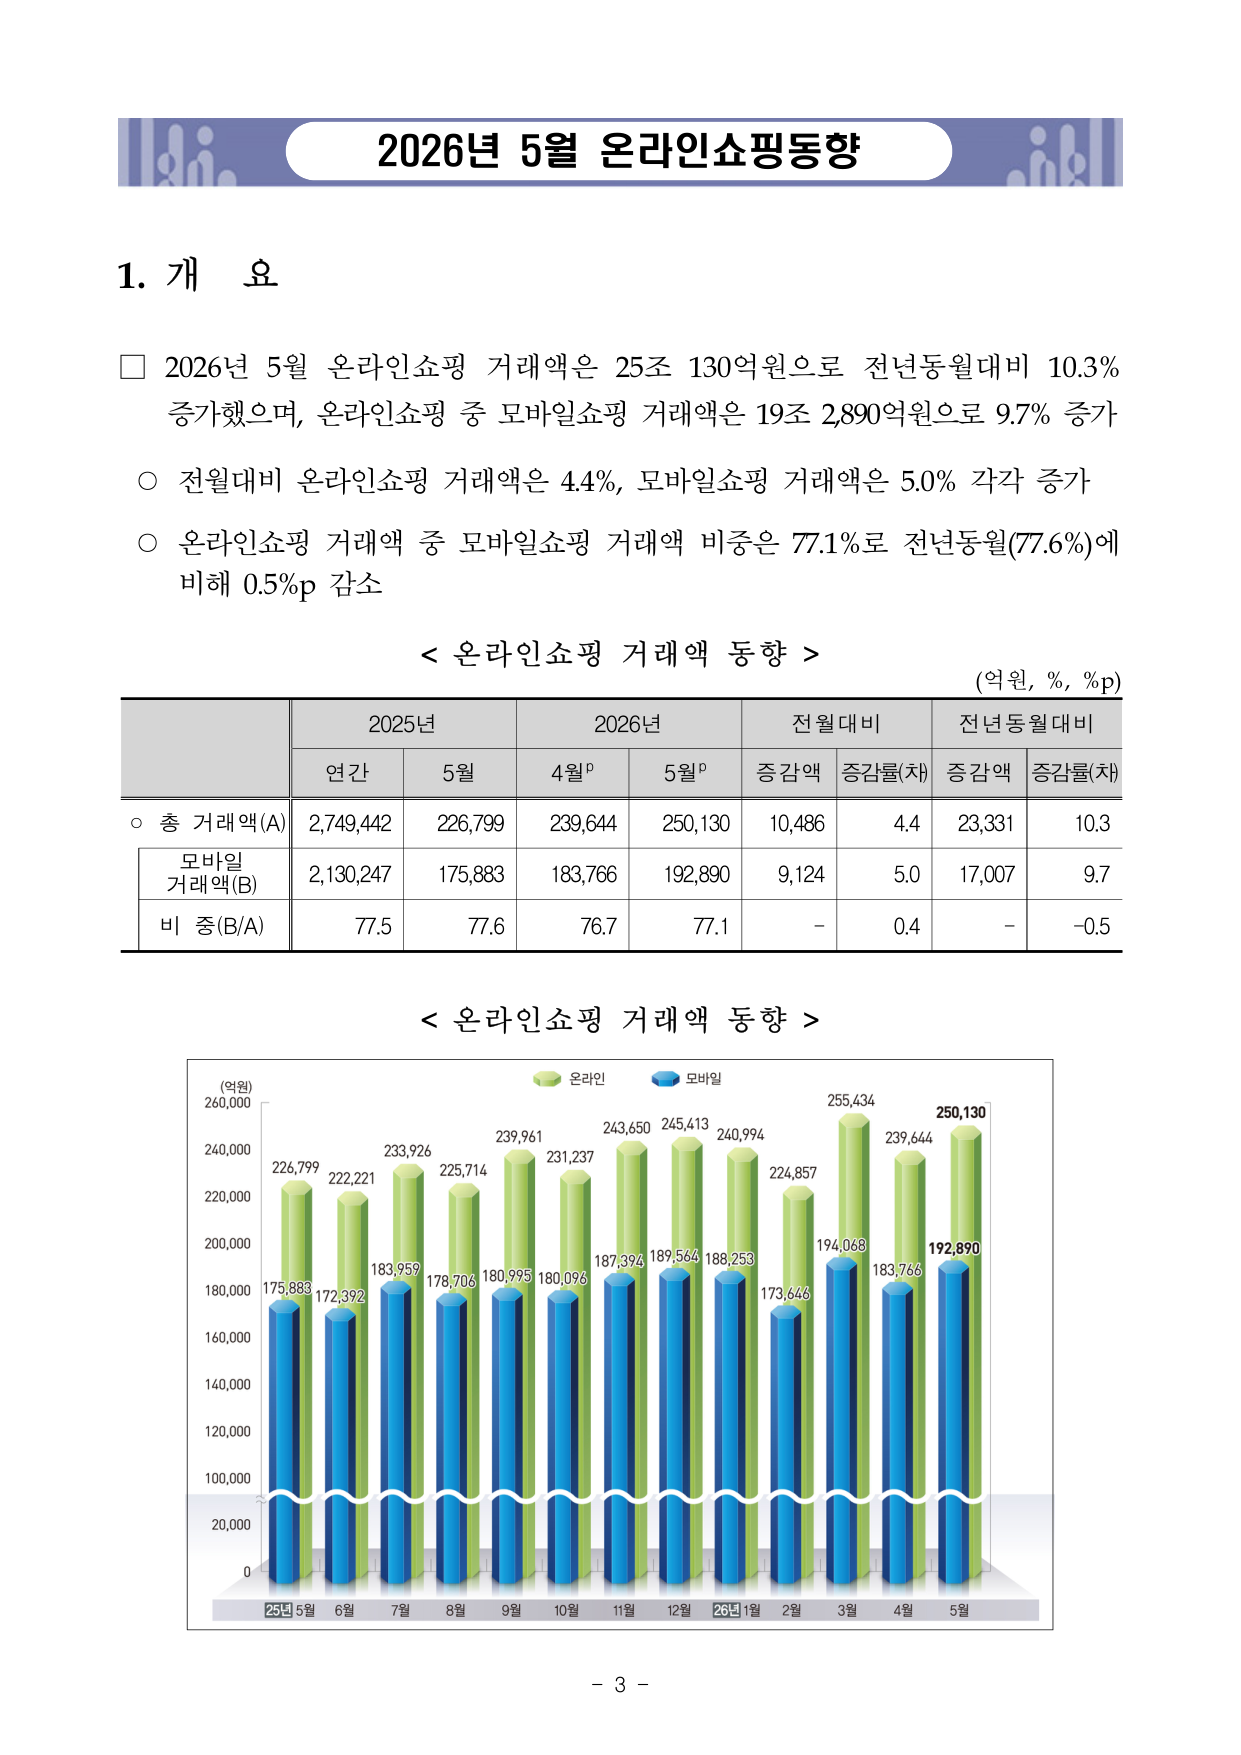

online_shopping_trend 2


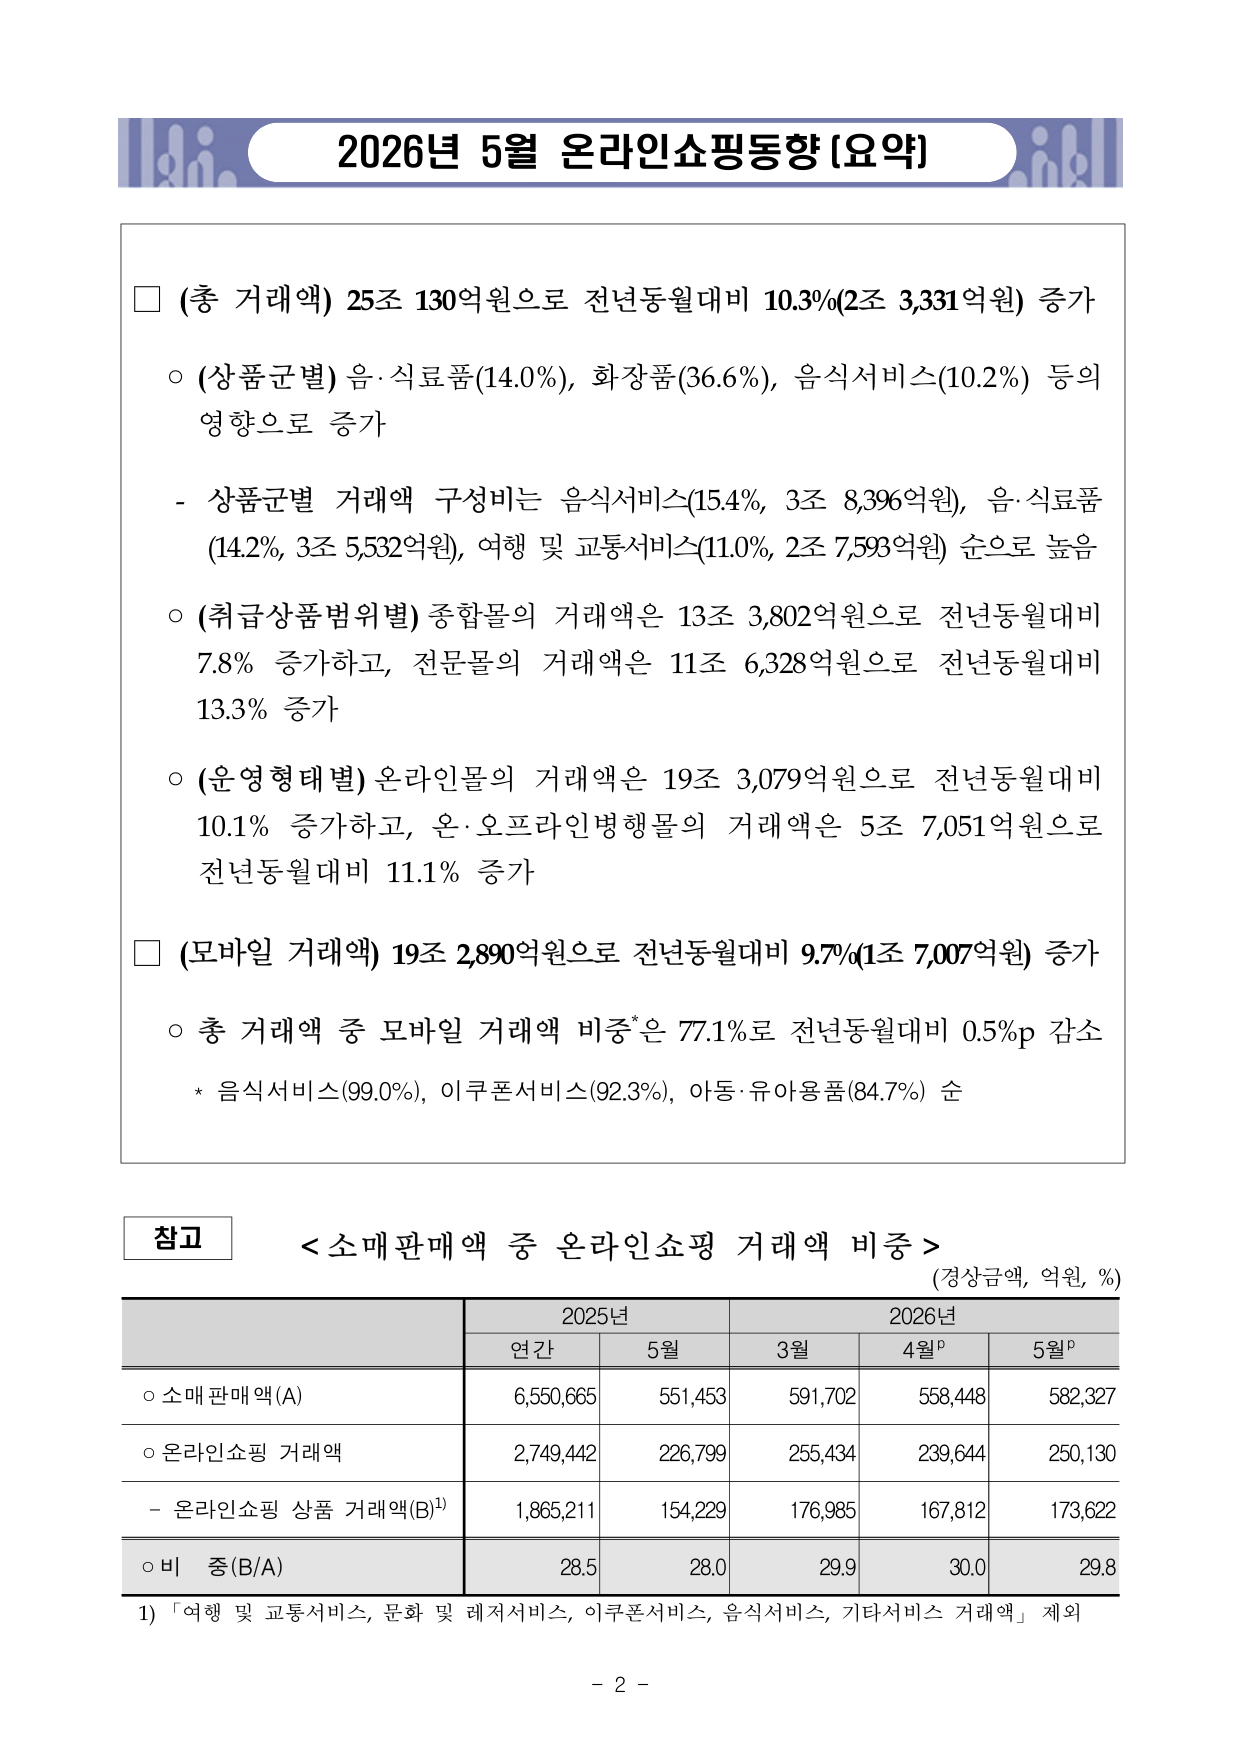

In [6]:
# 답변에 실제로 사용된 페이지 출처와 이미지를 확인
for m in metadatas:
    print(m["source"], m["page"])
    show(m["image_path"])


## 5. 여러 문서를 넘나드는 질의
컬렉션 하나에 두 문서를 함께 저장했기 때문에, 질문 내용에 따라 관련된 문서가 자동으로 선택됩니다.


2026년 4월 출생아 수는 **24,521명**이며, 합계출산율은 **0.93**입니다.
population_dynamics_survey 4


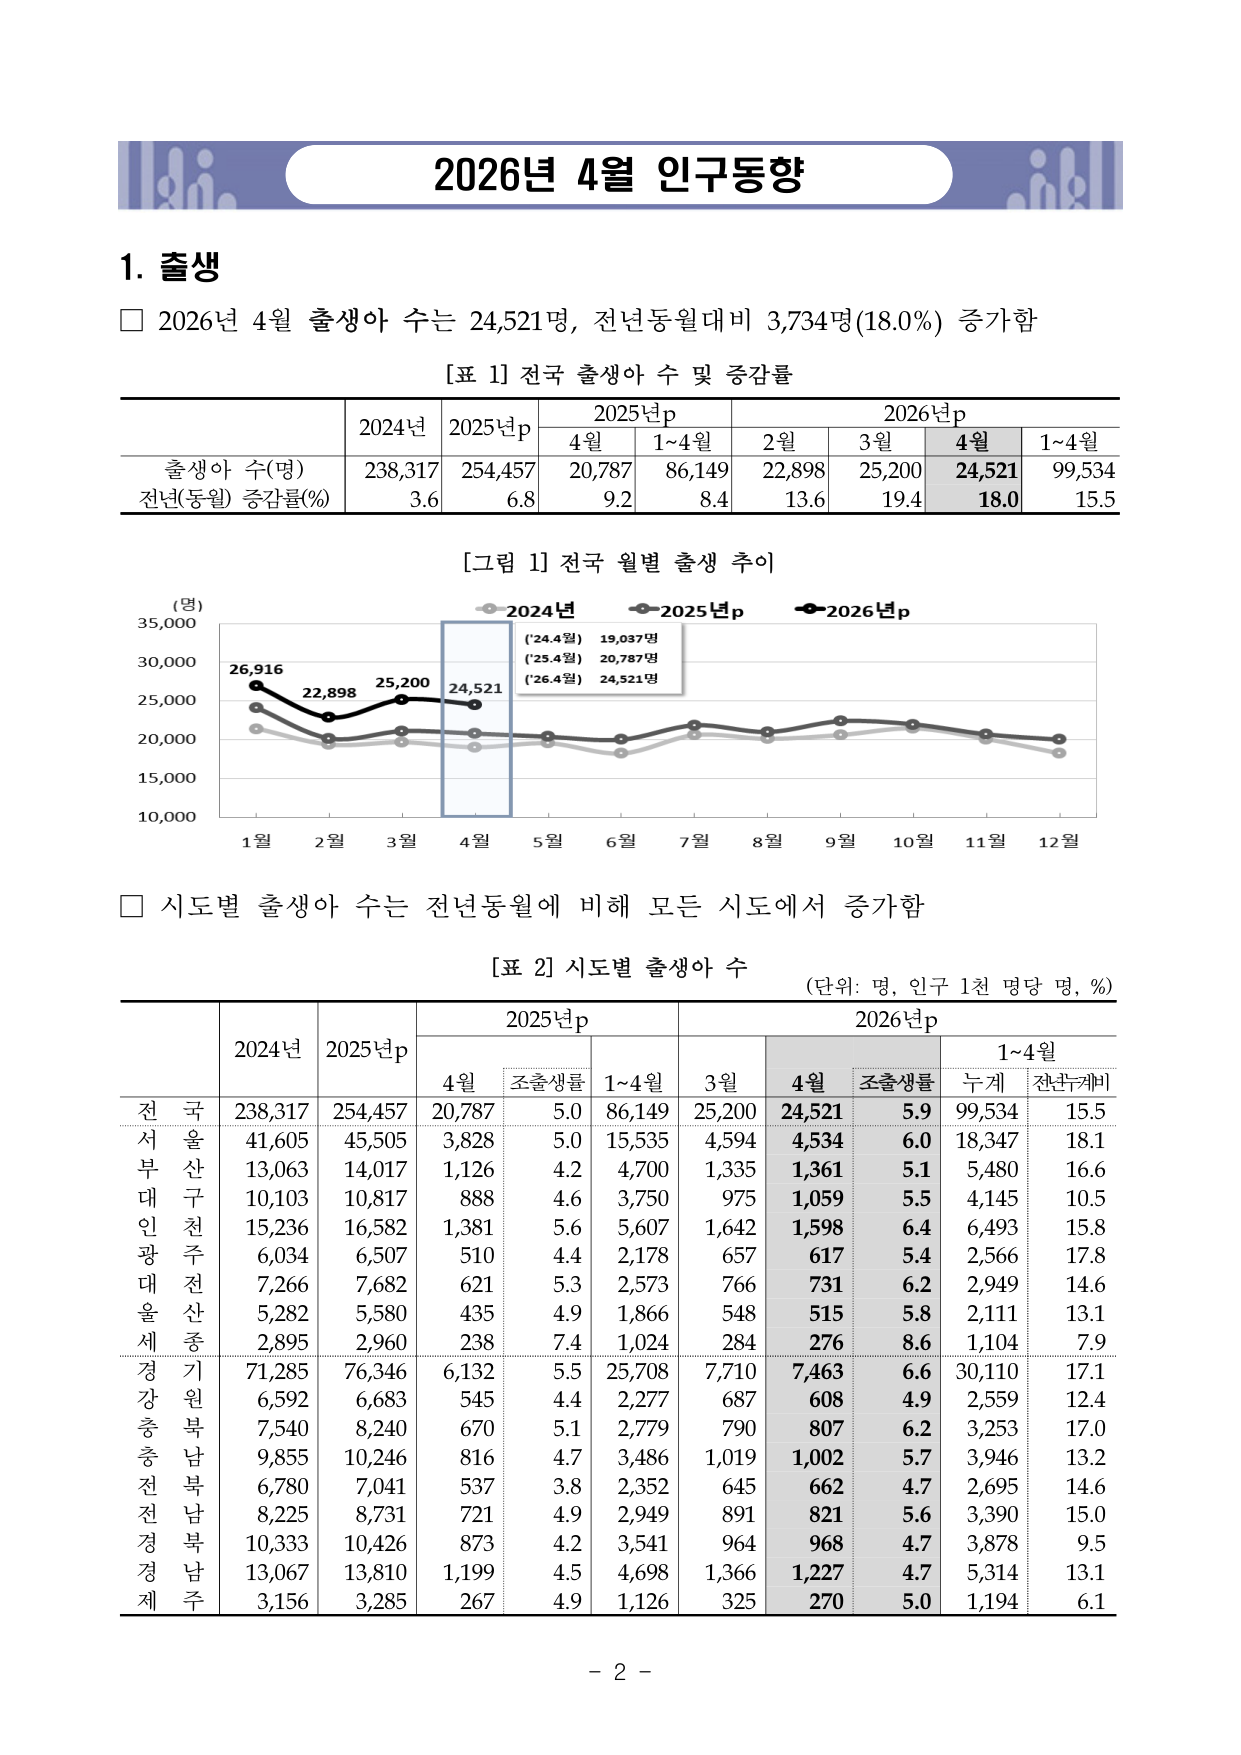

population_dynamics_survey 5


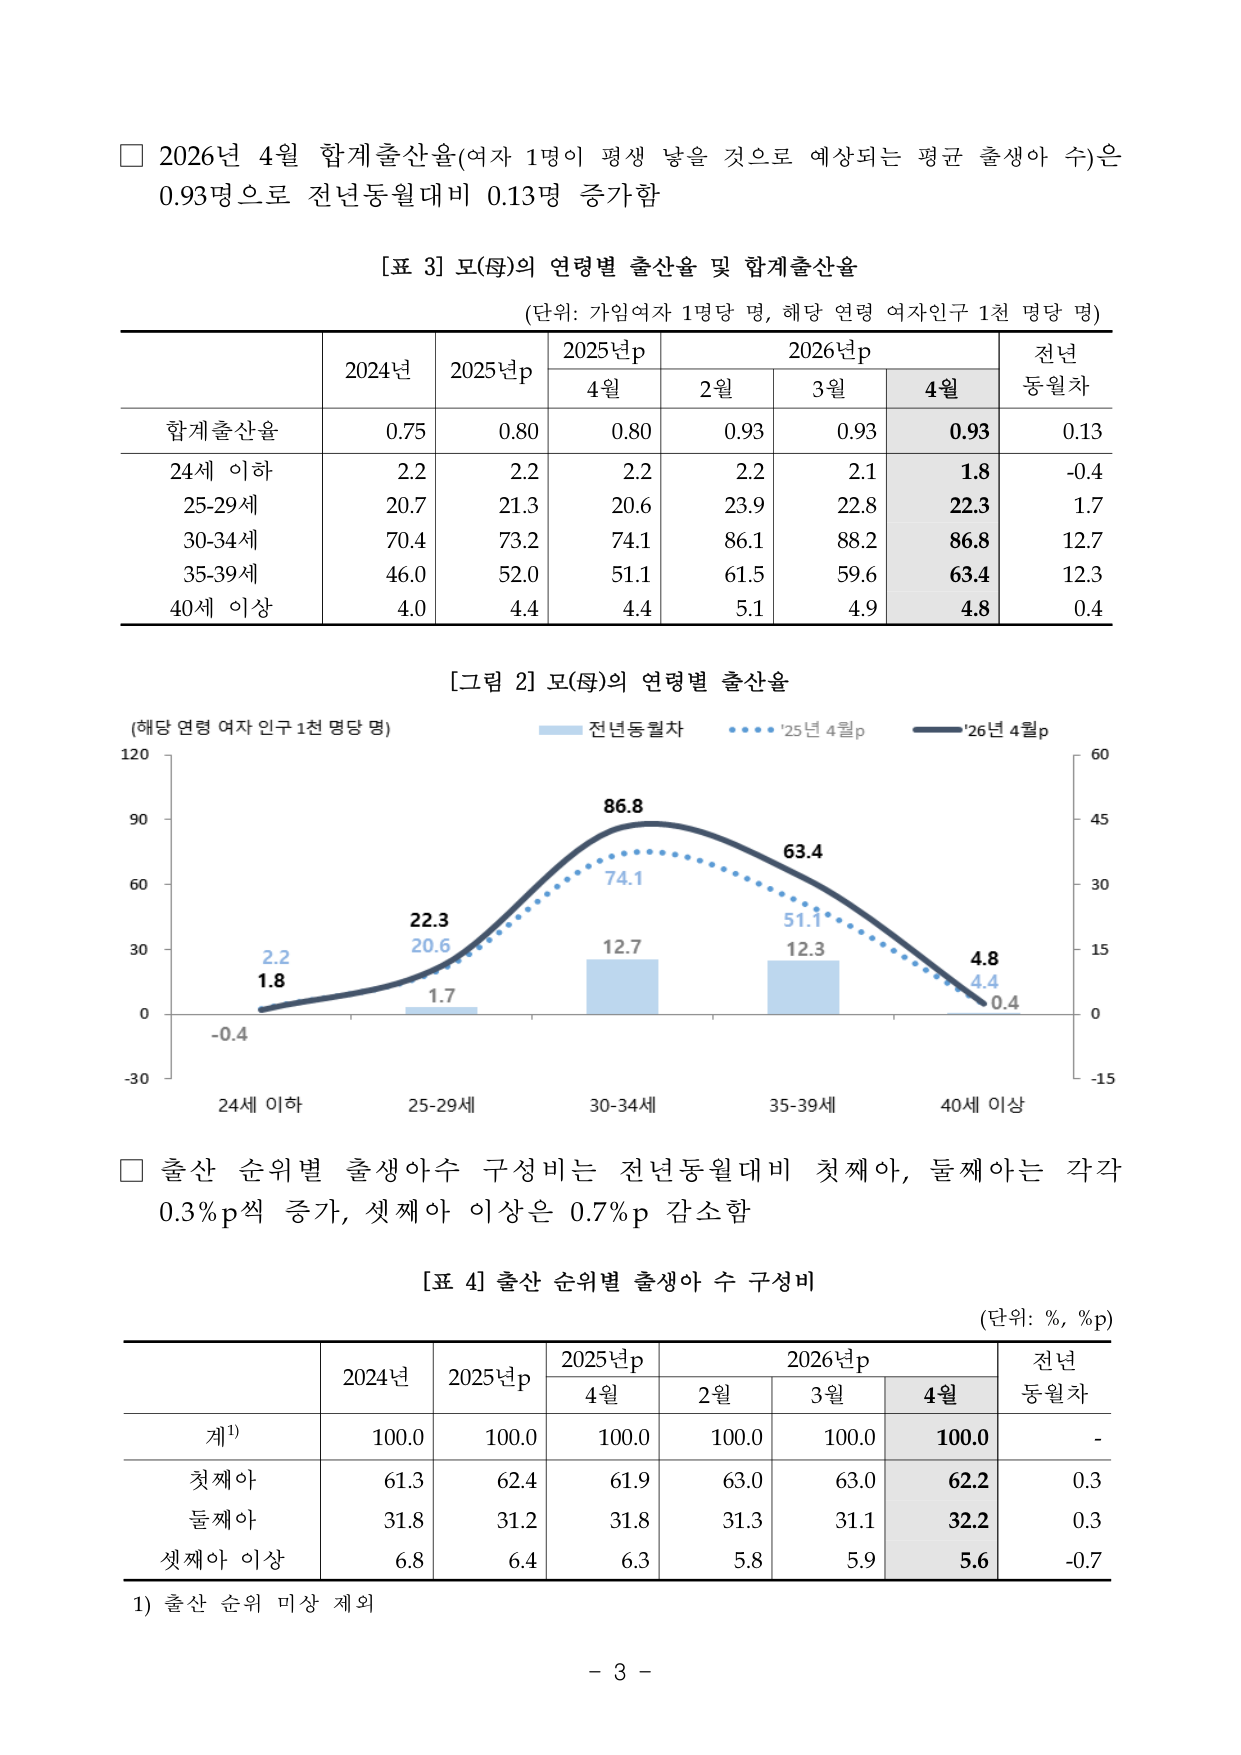

In [8]:
answer2, metadatas2 = ask_table("2026년 4월 출생아 수와 합계출산율은 각각 얼마야?")
print(answer2)

for m in metadatas2:
    print(m["source"], m["page"])
    show(m["image_path"])


## 정리
- 표 위주 문서는 **마크다운 텍스트본**으로 정확한 셀 값을 조회하고, **원본 이미지**로 레이아웃과 값을 검증하는 전략이 효과적입니다.
- 여러 문서를 하나의 컬렉션에 저장해도 임베딩 유사도만으로 올바른 출처가 검색됩니다.
